# Mouse 720762: EEG and LFP motifs across awake → isoflurane

**Owner:** Justin Yu  
**Recording:** `720762-20240221-v001.nwb`

This notebook produces the required analysis for three views of the same recording:

1. awake only,
2. isoflurane only,
3. the full awake-to-isoflurane interval.

It includes EEG motif detection, LFP motif detection, EEG and deep-LFP power spectra, a multi-channel LFP heatmap, a true spike raster, and a blocked-cross-validation state decoder as the ML extension. Expensive frequency-envelope calculations are cached so they do not need to be repeated.

> **Interpretation rule:** results from one mouse describe this recording; they do not establish a population-wide drug effect.


## 1. Setup

Run this notebook from anywhere inside the repository. It first looks for the NWB file on the Lexar flash drive and then in the repository's `data/raw` folder.

Use the project's Python environment. If the imports are missing, install them once with:

```bash
pip install pynwb h5py numpy pandas matplotlib scipy scikit-learn jupyter
```


In [1]:
from pathlib import Path
import json
import sys

PROJECT_ROOT = Path.cwd().resolve()
while PROJECT_ROOT.parent != PROJECT_ROOT and not (PROJECT_ROOT / "code" / "python" / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / "code" / "python" / "src").exists():
    raise RuntimeError("Could not locate the repository root")

LOCAL_DEPS = PROJECT_ROOT / ".python-deps"
if LOCAL_DEPS.exists() and str(LOCAL_DEPS) not in sys.path:
    sys.path.insert(0, str(LOCAL_DEPS))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import signal

PYTHON_ROOT = PROJECT_ROOT / "code" / "python"
if str(PYTHON_ROOT) not in sys.path:
    sys.path.insert(0, str(PYTHON_ROOT))

from src.mouse720762_analysis import (
    NWB_FILENAME,
    blocked_state_decoder,
    discover_state_motifs,
    eeg_channel_table,
    infer_state_windows,
    inspect_nwb,
    lfp_region_table,
    load_eeg_trace,
    load_envelope_cache,
    load_lfp_matrix,
    load_lfp_trace,
    load_matched_spike_rasters,
    match_motif_pairs,
    preprocess_envelope,
    save_envelope_cache,
)
from src.smooth_env import DEFAULT_FREQ_BANDS

OUTPUT_DIR = PROJECT_ROOT / "data" / "out" / "mouse720762"
CACHE_DIR = OUTPUT_DIR / "cache"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CACHE_DIR.mkdir(parents=True, exist_ok=True)

DATA_CANDIDATES = [
    Path("/Volumes/Lexar/allen-data/raw") / NWB_FILENAME,
    Path("/Volumes/Lexar/allen-project/data/raw") / NWB_FILENAME,
    PROJECT_ROOT / "data" / "raw" / NWB_FILENAME,
]
NWB_PATH = next((path for path in DATA_CANDIDATES if path.exists()), None)
if NWB_PATH is None:
    raise FileNotFoundError(
        "The recording is not finished downloading yet. Expected one of:\n"
        + "\n".join(str(path) for path in DATA_CANDIDATES)
    )

MIN_EXPECTED_BYTES = 20_000_000_000
if NWB_PATH.stat().st_size < MIN_EXPECTED_BYTES:
    raise RuntimeError(
        f"The NWB file is only {NWB_PATH.stat().st_size / 1e9:.2f} GB and is probably incomplete. "
        "Wait for the approximately 24.23 GB download to finish."
    )

print("Repository:", PROJECT_ROOT)
print("Recording:", NWB_PATH)
print(f"File size: {NWB_PATH.stat().st_size / 1e9:.2f} GB")
print("Outputs:", OUTPUT_DIR)


Repository: /Users/justinyu/.codex/.chatgpt-projects/g-p-6ac3dc2ab9988191b5b6b183a1586210/submission-repo
Recording: /Volumes/Lexar/allen-data/raw/720762-20240221-v001.nwb
File size: 26.01 GB
Outputs: /Users/justinyu/.codex/.chatgpt-projects/g-p-6ac3dc2ab9988191b5b6b183a1586210/submission-repo/data/out/mouse720762


## 2. Verify the recording and state boundaries

The notebook reads the labeled `behavioral_epoch` intervals instead of guessing when anesthesia began. Inspect the table before continuing. If the labels are missing or incorrect, set `WINDOWS` manually using the isoflurane-level trace and experiment notes.


In [2]:
metadata = inspect_nwb(NWB_PATH)
display(pd.Series({key: value for key, value in metadata.items() if key != "states"}, name="value"))
display(pd.DataFrame(metadata["states"]))

assert metadata["subject"] == "720762", f"Wrong mouse: {metadata['subject']}"
WINDOWS = infer_state_windows(NWB_PATH)
FULL_START = min(WINDOWS["awake"][0], WINDOWS["isoflurane"][0])
FULL_STOP = max(WINDOWS["awake"][1], WINDOWS["isoflurane"][1])
WINDOWS


file                                            720762-20240221-v001.nwb
subject                                                           720762
session_id                                                      20240221
session_description    isoflurane experiment with EEG and Neuropixels...
pharmacology           isoflurane (inhalation): induction at 5%, main...
acquisition_keys            [ElectricalSeriesEEG, LFP, isoflurane_level]
probes                                  [probeB, probeC, probeD, probeF]
Name: value, dtype: object

,state,start_s,stop_s
0,awake,752.40433,3147.55424
1,isoflurane,4648.27026,7023.87438


{'awake': (752.40433, 3147.55424), 'isoflurane': (4648.27026, 7023.87438)}

In [3]:
# Optional manual correction—only edit these values after inspecting the metadata.
# WINDOWS = {
#     "awake": (AWAKE_START_SECONDS, AWAKE_STOP_SECONDS),
#     "isoflurane": (ISO_START_SECONDS, ISO_STOP_SECONDS),
# }

for state, (start, stop) in WINDOWS.items():
    print(f"{state:12s}: {start:8.1f}–{stop:8.1f} s  ({(stop-start)/60:.1f} min)")


awake       :    752.4–  3147.6 s  (39.9 min)
isoflurane  :   4648.3–  7023.9 s  (39.6 min)


## 3. Choose EEG and LFP channels

The task notes recommend EEG channel **13** as frontal and channel **7** as somatosensory. In this recording channel 7 is marked invalid, so the notebook uses nearby valid somatosensory channel **9** (`SSp-bfd`) instead. It verifies both selected channels and reports their NWB anatomical labels.

For LFP, it automatically prefers a valid deep prefrontal channel in MOs, ACA, PL, IL, or ORB. The exact region and probe are printed rather than assumed.


In [4]:
eeg_channels = eeg_channel_table(NWB_PATH)
display(eeg_channels.loc[eeg_channels.channel.isin([7, 9, 13])])

EEG_CHANNELS = [13, 9]
for channel in EEG_CHANNELS:
    row = eeg_channels.loc[eeg_channels.channel == channel].iloc[0]
    if "is_data_valid" in row and not bool(row.is_data_valid):
        raise ValueError(f"EEG channel {channel} is marked invalid; select a nearby valid channel")

lfp_regions = lfp_region_table(NWB_PATH)
deep_prefixes = ("MOs6", "MOs5", "ACA6", "ACA5", "PL6", "PL5", "IL6", "IL5", "ORB6", "ORB5")
preferred = lfp_regions[lfp_regions.region.str.startswith(deep_prefixes, na=False)].copy()
preferred["preference_rank"] = preferred.region.map(
    lambda region: next(i for i, prefix in enumerate(deep_prefixes) if str(region).startswith(prefix))
)
preferred = preferred.sort_values(["preference_rank", "n_valid_channels"], ascending=[True, False])
display(preferred)
if preferred.empty:
    raise ValueError("No preferred deep prefrontal LFP region was found; inspect lfp_regions")

choice = preferred.iloc[0]
LFP_PROBE = str(choice.probe)
LFP_REGION = str(choice.region)
print(f"Selected LFP: {LFP_PROBE}, {LFP_REGION}, middle channel {choice.middle_channel}")


,channel,electrode_id,location,group,is_data_valid,probe_vertical_position,probe_horizontal_position,group_name,x,y,z,reference
7,7,7,VISa,EEG array pynwb.ecephys.ElectrodeGroup at 0x48...,False,-1,-1,EEG array,290.0,26.0,119.0,"stainless steel skull screw, left CB"
9,9,9,SSp-bfd,EEG array pynwb.ecephys.ElectrodeGroup at 0x48...,True,-1,-1,EEG array,231.0,51.0,97.0,"stainless steel skull screw, left CB"
13,13,13,MOs,EEG array pynwb.ecephys.ElectrodeGroup at 0x48...,True,-1,-1,EEG array,120.0,63.0,172.0,"stainless steel skull screw, left CB"


,probe,region,n_valid_channels,first_channel,last_channel,middle_channel,preference_rank
60,probeF,MOs5,41,293,333,313,1
59,probeF,PL5,78,213,292,254,5


Selected LFP: probeF, MOs5, middle channel 313


## 4. Quick signal-quality check

These short plots finish quickly and should be inspected before running motif discovery. Large flat sections, clipping, or overwhelming 60 Hz activity indicate a bad channel.


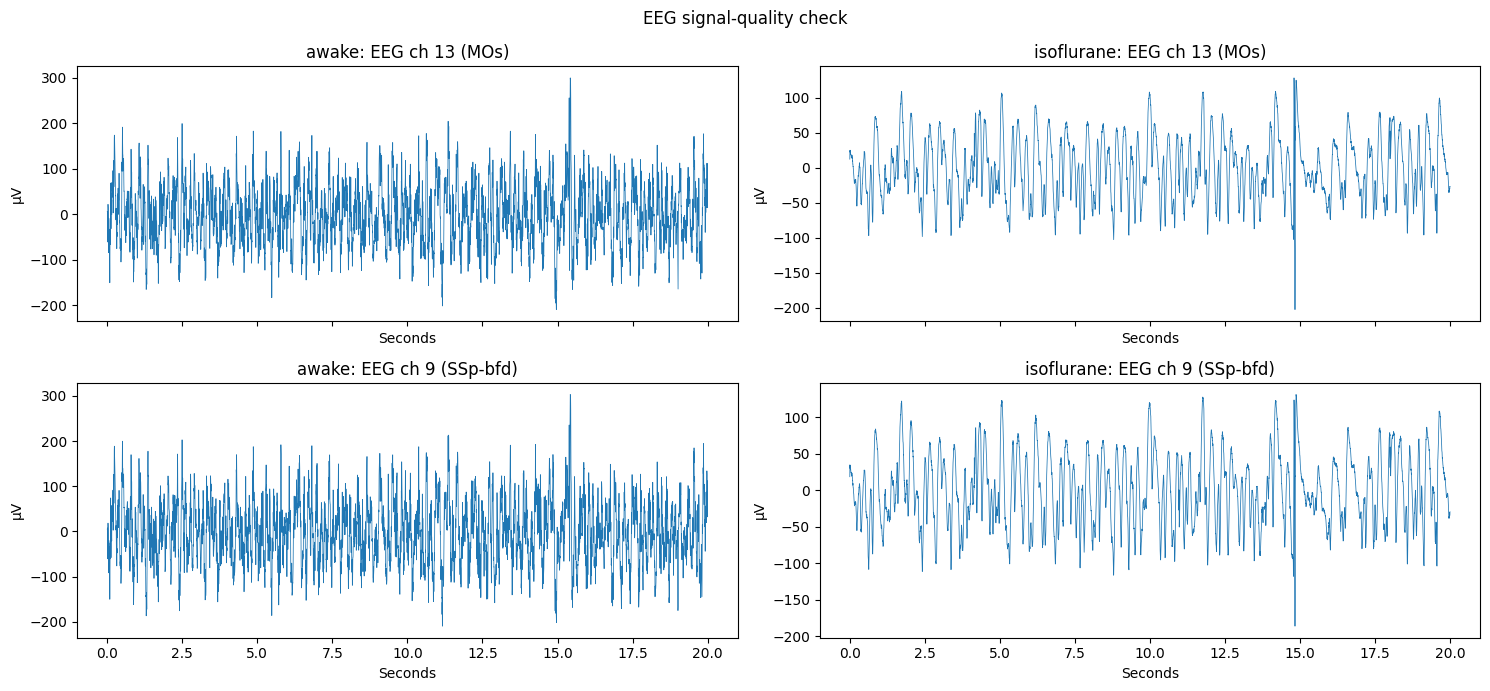

In [5]:
def centered_window(state, duration=20):
    start, stop = WINDOWS[state]
    middle = (start + stop) / 2
    return middle - duration / 2, middle + duration / 2

fig, axes = plt.subplots(2, 2, figsize=(15, 7), sharex="col")
for column, state in enumerate(("awake", "isoflurane")):
    start, stop = centered_window(state)
    for row_index, channel in enumerate(EEG_CHANNELS):
        trace = load_eeg_trace(NWB_PATH, channel, start, stop, target_fs=250)
        axes[row_index, column].plot(trace.time_s - trace.time_s[0], trace.values_uv, lw=0.55)
        axes[row_index, column].set_title(f"{state}: EEG ch {channel} ({trace.location})")
        axes[row_index, column].set_ylabel("µV")
        axes[row_index, column].set_xlabel("Seconds")
fig.suptitle("EEG signal-quality check")
plt.tight_layout()
plt.show()


## 5. EEG power spectrum

Welch's method summarizes average power by frequency. We use matched two-minute windows from the middle of awake and isoflurane, plus the complete awake-to-isoflurane interval. All three use identical spectral parameters and axes.


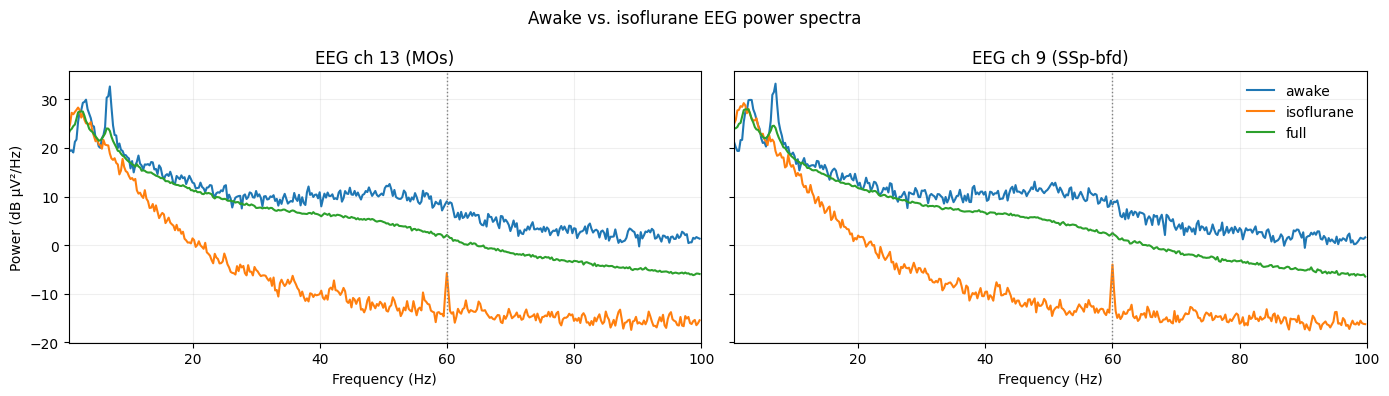

In [6]:
def middle_window(window, duration=120):
    start, stop = window
    duration = min(duration, stop - start)
    middle = (start + stop) / 2
    return middle - duration / 2, middle + duration / 2

fig, axes = plt.subplots(1, len(EEG_CHANNELS), figsize=(14, 4), sharey=True)
psd_rows = []
PSD_WINDOWS = {
    "awake": middle_window(WINDOWS["awake"]),
    "isoflurane": middle_window(WINDOWS["isoflurane"]),
    "full": (FULL_START, FULL_STOP),
}
PSD_COLORS = {"awake": "tab:blue", "isoflurane": "tab:orange", "full": "tab:green"}

for ax, channel in zip(axes, EEG_CHANNELS):
    for state, (start, stop) in PSD_WINDOWS.items():
        color = PSD_COLORS[state]
        trace = load_eeg_trace(NWB_PATH, channel, start, stop, target_fs=250)
        frequency, power = signal.welch(
            trace.values_uv - np.median(trace.values_uv),
            fs=trace.fs_hz,
            nperseg=int(4 * trace.fs_hz),
            noverlap=int(2 * trace.fs_hz),
            average="median",
        )
        keep = (frequency >= 0.5) & (frequency <= 100)
        ax.plot(frequency[keep], 10 * np.log10(power[keep] + np.finfo(float).tiny), label=state, color=color)
        psd_rows.extend(
            {"channel": channel, "location": trace.location, "state": state, "frequency_hz": f, "power_uv2_hz": p}
            for f, p in zip(frequency[keep], power[keep])
        )
    ax.axvline(60, color="0.5", ls=":", lw=1)
    ax.set_title(f"EEG ch {channel} ({trace.location})")
    ax.set_xlabel("Frequency (Hz)")
    ax.set_xlim(0.5, 100)
    ax.grid(alpha=0.2)
axes[0].set_ylabel("Power (dB µV²/Hz)")
axes[-1].legend(frameon=False)
fig.suptitle("Awake vs. isoflurane EEG power spectra")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "eeg_power_spectra.png", dpi=180)
plt.show()

pd.DataFrame(psd_rows).to_csv(OUTPUT_DIR / "eeg_power_spectra.csv", index=False)


### 5b. Deep-LFP power spectrum

The same awake, isoflurane, and full-recording comparison is repeated for the selected deep prefrontal LFP channel. This directly tests the task note that deep LFP may retain higher-frequency structure that is less visible at the cortical EEG surface.


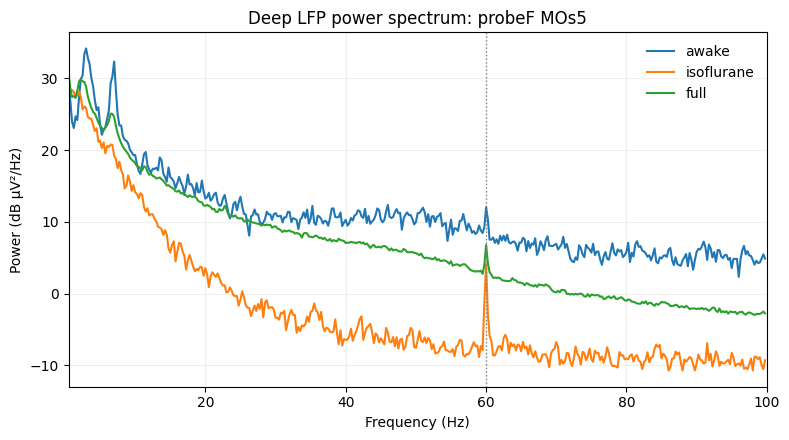

In [7]:
fig, ax = plt.subplots(figsize=(8, 4.5))
lfp_psd_rows = []
for state, (start, stop) in PSD_WINDOWS.items():
    trace = load_lfp_trace(NWB_PATH, LFP_PROBE, LFP_REGION, start, stop, target_fs=250)
    frequency, power = signal.welch(
        trace.values_uv - np.median(trace.values_uv),
        fs=trace.fs_hz,
        nperseg=int(4 * trace.fs_hz),
        noverlap=int(2 * trace.fs_hz),
        average="median",
    )
    keep = (frequency >= 0.5) & (frequency <= 100)
    ax.plot(
        frequency[keep],
        10 * np.log10(power[keep] + np.finfo(float).tiny),
        label=state,
        color=PSD_COLORS[state],
    )
    lfp_psd_rows.extend(
        {
            "probe": LFP_PROBE,
            "region": LFP_REGION,
            "channel": trace.channel,
            "state": state,
            "frequency_hz": f,
            "power_uv2_hz": p,
        }
        for f, p in zip(frequency[keep], power[keep])
    )
ax.axvline(60, color="0.5", ls=":", lw=1)
ax.set(
    title=f"Deep LFP power spectrum: {LFP_PROBE} {LFP_REGION}",
    xlabel="Frequency (Hz)",
    ylabel="Power (dB µV²/Hz)",
    xlim=(0.5, 100),
)
ax.grid(alpha=0.2)
ax.legend(frameon=False)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "lfp_power_spectra.png", dpi=180)
plt.show()
pd.DataFrame(lfp_psd_rows).to_csv(OUTPUT_DIR / "lfp_power_spectra.csv", index=False)


## 6. Preprocess and cache the full awake-to-isoflurane interval

Motif preprocessing is the expensive step. Each selected channel is loaded once, downsampled to 250 Hz, notch-filtered at 60 Hz, divided into frequency bands, converted to Hilbert-amplitude envelopes, smoothed, and z-scored over the common full interval.

Using one common normalization before slicing awake and isoflurane makes their motif patterns more directly comparable. The default six-band configuration matches the team's current merged NWB motif pipeline and is computationally practical. Increase the band resolution only after this version runs successfully.


In [8]:
BANDS = DEFAULT_FREQ_BANDS.copy()
TARGET_FS = 250.0
N_NULL = 20
SEED = 0

def cached_envelope(kind, cache_name, loader):
    cache_path = CACHE_DIR / cache_name
    if cache_path.exists():
        cached = load_envelope_cache(cache_path)
        same_bands = cached["bands"].shape == BANDS.shape and np.allclose(cached["bands"], BANDS)
        covers_interval = cached["time_s"][0] <= FULL_START + 15 and cached["time_s"][-1] >= FULL_STOP - 15
        if same_bands and covers_interval:
            print("Loaded cache:", cache_path.name)
            return cached["envelope"], cached["time_s"], float(cached["fs_hz"]), cached
        print("Ignoring incompatible cache:", cache_path.name)
    trace = loader()
    envelope, time_s = preprocess_envelope(trace, BANDS, notch_60hz=True)
    save_envelope_cache(cache_path, envelope, time_s, trace, BANDS)
    print("Created cache:", cache_path.name)
    return envelope, time_s, trace.fs_hz, {"location": trace.location, "channel": trace.channel, "source": trace.source}

eeg_envelopes = {}
for channel in EEG_CHANNELS:
    eeg_envelopes[channel] = cached_envelope(
        "EEG",
        f"eeg_channel_{channel}_envelope.npz",
        lambda channel=channel: load_eeg_trace(NWB_PATH, channel, FULL_START, FULL_STOP, TARGET_FS),
    )

lfp_envelope = cached_envelope(
    "LFP",
    f"lfp_{LFP_PROBE}_{LFP_REGION.replace('/', '-')}_envelope.npz",
    lambda: load_lfp_trace(NWB_PATH, LFP_PROBE, LFP_REGION, FULL_START, FULL_STOP, TARGET_FS),
)


Loaded cache: eeg_channel_13_envelope.npz
Loaded cache: eeg_channel_9_envelope.npz


Created cache: lfp_probeF_MOs5_envelope.npz


## 7. EEG motif detection: awake, isoflurane, and full recording

Each condition is analyzed independently. A motif is retained only if it is larger than motifs found in circularly shifted null data. The detector returns opponent pairs: `M1+` and `M1−` are opposite poles of the same spectral pattern.


In [9]:
eeg_motif_results = {}
for channel, (envelope, time_s, fs_hz, info) in eeg_envelopes.items():
    print(f"\nEEG channel {channel}")
    eeg_motif_results[channel] = discover_state_motifs(
        envelope, time_s, fs_hz, WINDOWS, n_null=N_NULL, seed=SEED, verbose=True
    )
    print({state: result.n_motifs for state, result in eeg_motif_results[channel].items()})



EEG channel 13
  [real data] 1848 timepoints, candidates per threshold: [6, 7, 7, 7, 7] (0.1s)


  [null 1/20] 1808 timepoints, candidates per threshold: [6, 6, 6, 7, 7] (0.0s)


  [null 2/20] 1832 timepoints, candidates per threshold: [6, 6, 6, 7, 7] (0.0s)


  [null 3/20] 1805 timepoints, candidates per threshold: [6, 6, 6, 7, 7] (0.0s)


  [null 4/20] 1789 timepoints, candidates per threshold: [6, 6, 6, 7, 7] (0.0s)


  [null 5/20] 1789 timepoints, candidates per threshold: [6, 6, 6, 7, 7] (0.0s)


... (117 outputs left out)

  [null 18/20] 5038 timepoints, candidates per threshold: [18, 27, 36, 41, 46] (0.4s)


  [null 19/20] 5018 timepoints, candidates per threshold: [15, 23, 33, 40, 48] (0.3s)


  [null 20/20] 5059 timepoints, candidates per threshold: [15, 16, 30, 37, 44] (0.3s)


{'awake': 0, 'isoflurane': 0, 'full': 1}


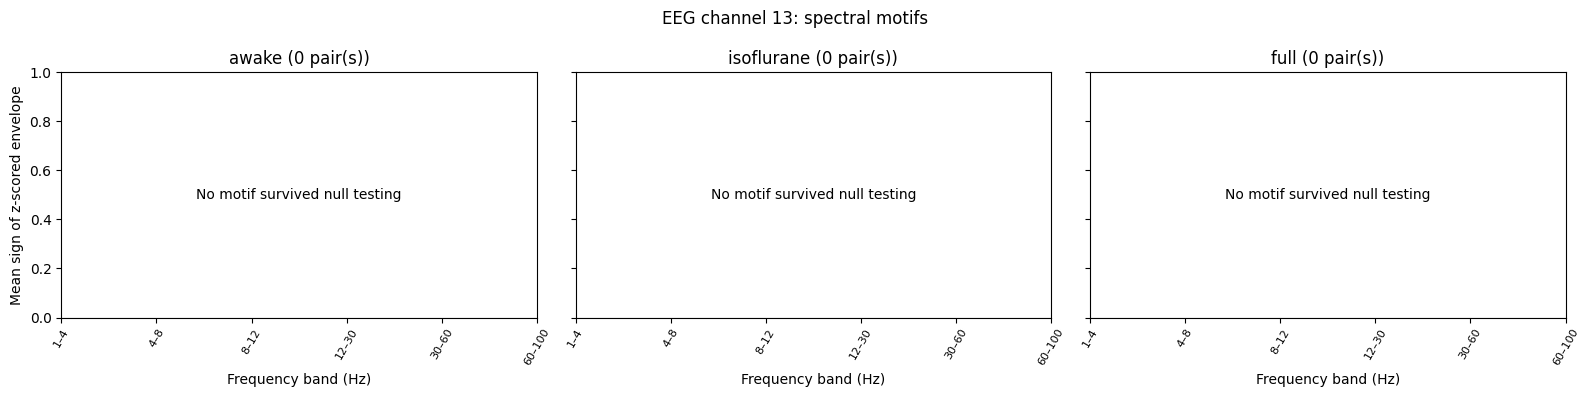

,motif_a,motif_b,correlation,abs_correlation,flipped


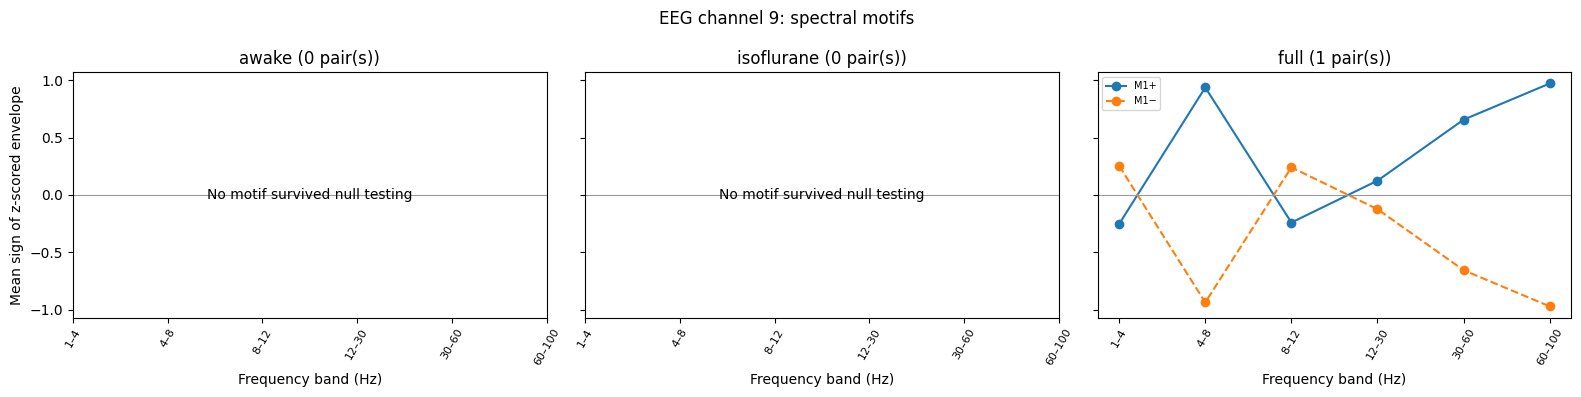

,motif_a,motif_b,correlation,abs_correlation,flipped


In [10]:
def plot_motif_results(results, title, output_name):
    fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
    band_labels = [f"{lo:g}–{hi:g}" for lo, hi in BANDS]
    for ax, state in zip(axes, ("awake", "isoflurane", "full")):
        result = results[state]
        if not result.n_motifs:
            ax.text(0.5, 0.5, "No motif survived null testing", ha="center", va="center", transform=ax.transAxes)
        for index in range(result.n_motifs):
            ax.plot(result.motifs[:, index], "-o", label=f"M{index+1}+")
            ax.plot(result.motifs[:, index + result.n_motifs], "--o", label=f"M{index+1}−")
        ax.axhline(0, color="0.6", lw=0.8)
        ax.set_xticks(range(len(BANDS)), band_labels, rotation=60, fontsize=8)
        ax.set_title(f"{state} ({result.n_motifs} pair(s))")
        ax.set_xlabel("Frequency band (Hz)")
        if result.n_motifs:
            ax.legend(fontsize=7)
    axes[0].set_ylabel("Mean sign of z-scored envelope")
    fig.suptitle(title)
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / output_name, dpi=180)
    plt.show()

for channel, results in eeg_motif_results.items():
    plot_motif_results(results, f"EEG channel {channel}: spectral motifs", f"eeg_channel_{channel}_motifs.png")
    display(match_motif_pairs(results["awake"], results["isoflurane"]))


## 8. LFP motif detection

The same tested detector and frequency bands are applied to one anatomically labeled deep LFP channel. This creates a fair EEG-versus-LFP comparison.


  [real data] 1611 timepoints, candidates per threshold: [4, 5, 7, 7, 7] (0.1s)


  [null 1/20] 1606 timepoints, candidates per threshold: [5, 7, 7, 7, 7] (0.0s)


  [null 2/20] 1632 timepoints, candidates per threshold: [6, 8, 8, 8, 8] (0.0s)


  [null 3/20] 1670 timepoints, candidates per threshold: [5, 5, 7, 7, 7] (0.0s)


  [null 4/20] 1610 timepoints, candidates per threshold: [6, 8, 8, 8, 8] (0.0s)


  [null 5/20] 1610 timepoints, candidates per threshold: [6, 8, 8, 8, 8] (0.1s)


... (54 outputs left out)

  [null 18/20] 4508 timepoints, candidates per threshold: [15, 16, 28, 36, 45] (0.3s)


  [null 19/20] 4383 timepoints, candidates per threshold: [9, 20, 31, 42, 50] (0.2s)


  [null 20/20] 4455 timepoints, candidates per threshold: [8, 12, 18, 28, 37] (0.3s)


{'awake': 0, 'isoflurane': 0, 'full': 1}


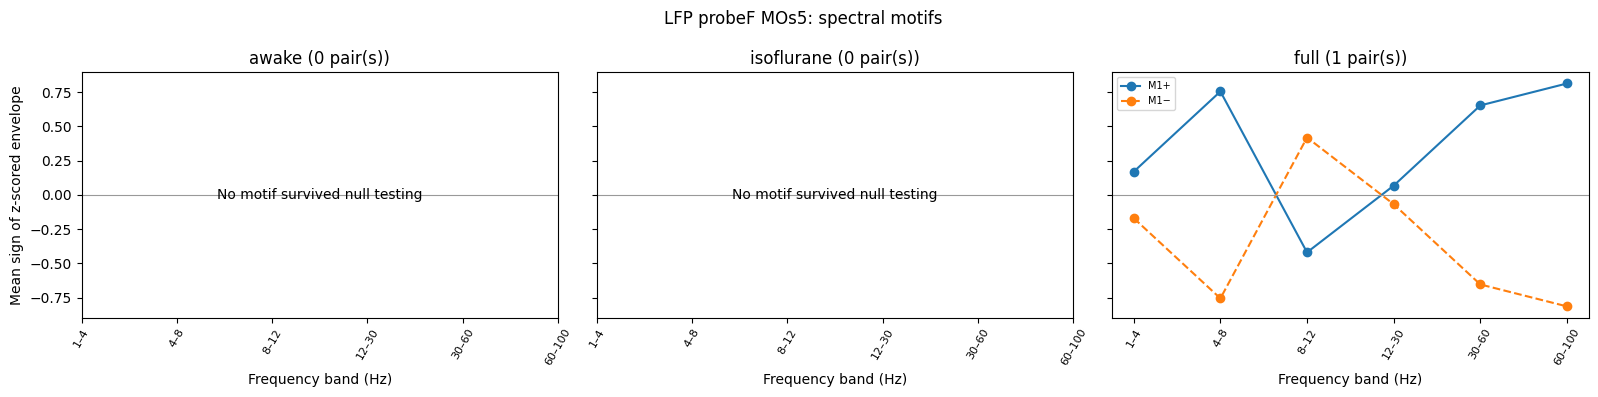

,motif_a,motif_b,correlation,abs_correlation,flipped


In [11]:
lfp_env, lfp_time, lfp_fs, lfp_info = lfp_envelope
lfp_motif_results = discover_state_motifs(
    lfp_env, lfp_time, lfp_fs, WINDOWS, n_null=N_NULL, seed=SEED, verbose=True
)
print({state: result.n_motifs for state, result in lfp_motif_results.items()})
plot_motif_results(
    lfp_motif_results,
    f"LFP {LFP_PROBE} {LFP_REGION}: spectral motifs",
    "lfp_motifs.png",
)
display(match_motif_pairs(lfp_motif_results["awake"], lfp_motif_results["isoflurane"]))


## 9. Multi-channel LFP heatmap

LFP is continuous, so this is properly called a **channel-by-time heatmap**, not a spike raster. Identical 30-second windows and robust color limits make awake and isoflurane visually comparable.


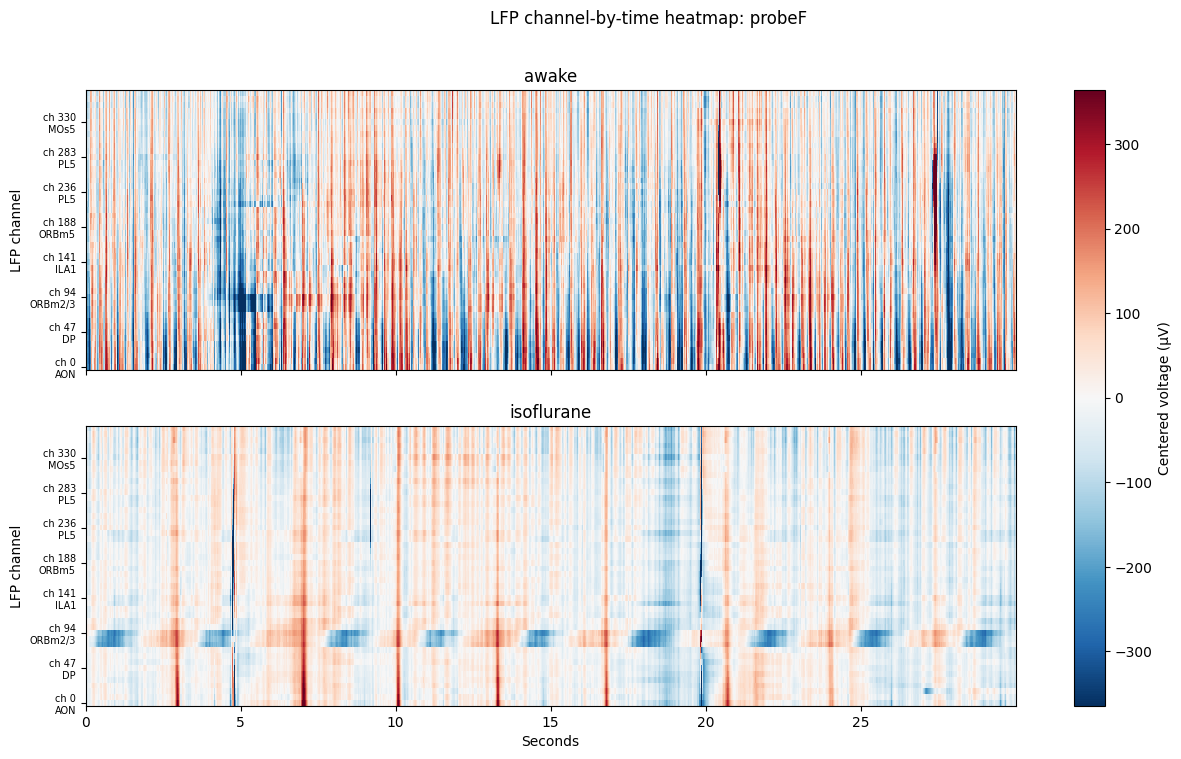

In [12]:
lfp_windows = {}
for state in ("awake", "isoflurane"):
    start, stop = centered_window(state, duration=30)
    lfp_windows[state] = load_lfp_matrix(NWB_PATH, LFP_PROBE, start, stop, max_channels=48, target_fs=250)

all_values = np.concatenate([np.abs(item["values_uv"]).ravel() for item in lfp_windows.values()])
limit = np.percentile(all_values, 99)
fig, axes = plt.subplots(2, 1, figsize=(15, 8), sharex=True)
for ax, state in zip(axes, ("awake", "isoflurane")):
    item = lfp_windows[state]
    centered = item["values_uv"] - np.median(item["values_uv"], axis=0)
    image = ax.imshow(
        centered.T,
        aspect="auto",
        origin="lower",
        cmap="RdBu_r",
        vmin=-limit,
        vmax=limit,
        extent=[0, centered.shape[0] / item["fs_hz"], -0.5, centered.shape[1] - 0.5],
        interpolation="none",
    )
    ticks = np.arange(0, len(item["channels"]), max(1, len(item["channels"]) // 8))
    ax.set_yticks(ticks, [f"ch {item['channels'][i]}\n{item['locations'][i]}" for i in ticks], fontsize=7)
    ax.set_ylabel("LFP channel")
    ax.set_title(state)
axes[-1].set_xlabel("Seconds")
fig.colorbar(image, ax=axes, label="Centered voltage (µV)")
fig.suptitle(f"LFP channel-by-time heatmap: {LFP_PROBE}")
plt.savefig(OUTPUT_DIR / "lfp_heatmap.png", dpi=180, bbox_inches="tight")
plt.show()


## 10. True neuronal spike raster

Each row below is one sorted neuron and each tick is one spike. The same neurons are shown in both matched 60-second windows, selected by their total activity across both states. This satisfies the raster requirement without incorrectly treating continuous LFP as discrete spikes.


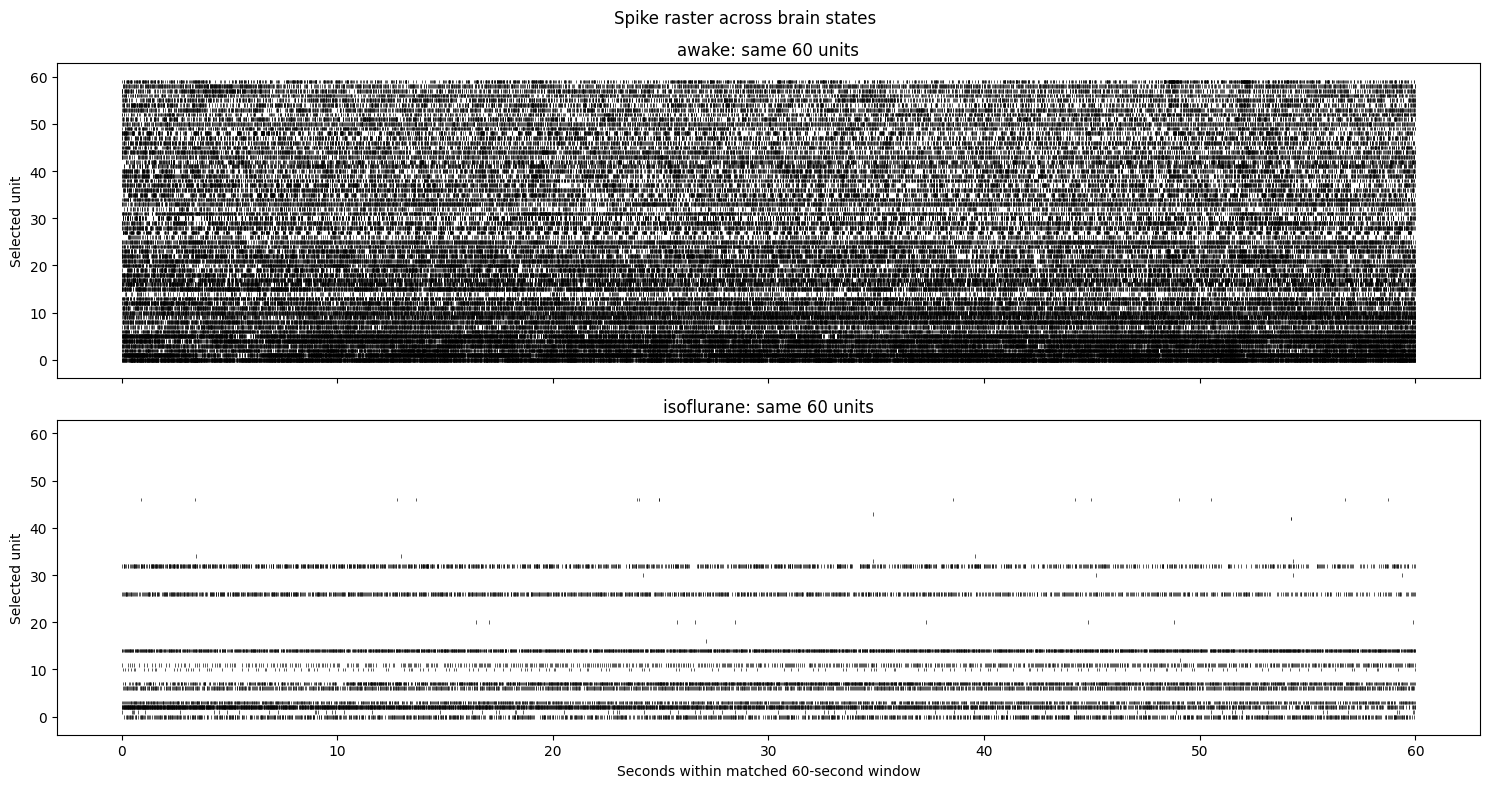

,state,units,spikes
0,awake,60,163656
1,isoflurane,60,15175


In [13]:
fig, axes = plt.subplots(2, 1, figsize=(15, 8), sharex=True)
raster_summaries = []
RASTER_WINDOWS = {
    state: middle_window(WINDOWS[state], duration=60)
    for state in ("awake", "isoflurane")
}
matched_spikes, matched_units = load_matched_spike_rasters(NWB_PATH, RASTER_WINDOWS, max_units=60)
for ax, state in zip(axes, ("awake", "isoflurane")):
    start, stop = RASTER_WINDOWS[state]
    relative = [spikes - start for spikes in matched_spikes[state]]
    ax.eventplot(relative, colors="black", lineoffsets=np.arange(len(relative)), linelengths=0.8, linewidths=0.45)
    ax.set_ylabel("Selected unit")
    ax.set_title(f"{state}: same {len(relative)} units")
    raster_summaries.append({"state": state, "units": len(relative), "spikes": int(sum(len(x) for x in relative))})
axes[-1].set_xlabel("Seconds within matched 60-second window")
fig.suptitle("Spike raster across brain states")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "spike_raster.png", dpi=180)
plt.show()
pd.DataFrame(raster_summaries)


## 11. ML extension: block-held-out brain-state decoding

A logistic-regression classifier tests whether the multiband envelope contains enough information to distinguish awake from isoflurane. Randomly splitting individual seconds would be misleading because neighboring signal values are highly correlated. Instead, entire contiguous 30-second blocks are held out.

- **50% balanced accuracy:** chance-level discrimination.
- **Above 50%:** frequency-band envelopes contain state information.
- This is cross-validated prediction, not proof that anesthesia caused every difference.


,signal,balanced_accuracy,n_seconds,n_blocks
0,EEG channel 13,100.0%,4752,159
1,EEG channel 9,100.0%,4752,159
2,LFP probeF MOs5,100.0%,4752,159


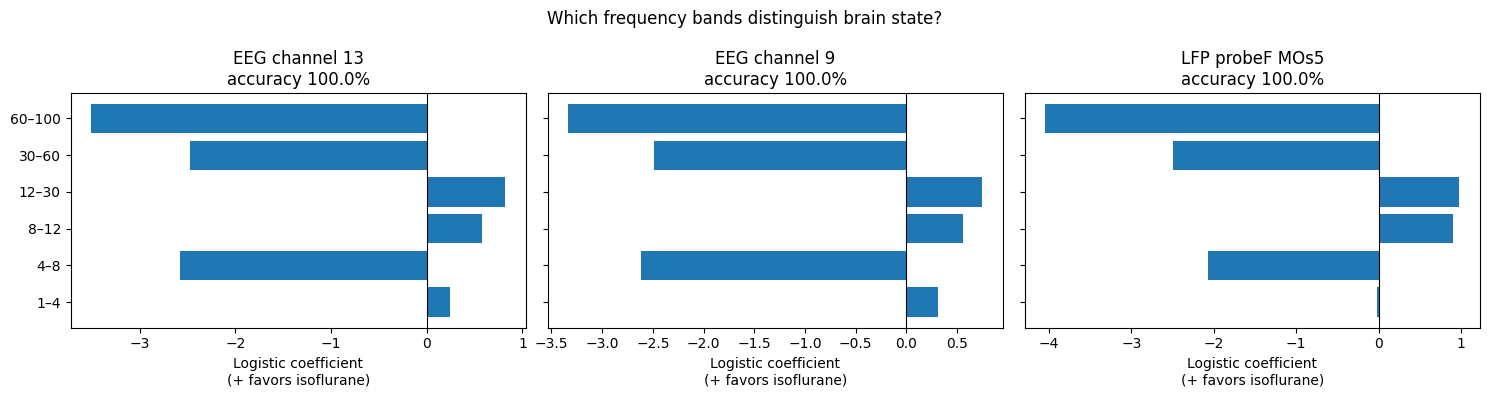

In [14]:
decoder_rows = []
decoder_details = {}
for name, (envelope, time_s, fs_hz, _) in {
    **{f"EEG channel {channel}": value for channel, value in eeg_envelopes.items()},
    f"LFP {LFP_PROBE} {LFP_REGION}": lfp_envelope,
}.items():
    result = blocked_state_decoder(envelope, time_s, fs_hz, WINDOWS, block_seconds=30, n_splits=5)
    decoder_details[name] = result
    decoder_rows.append(
        {
            "signal": name,
            "balanced_accuracy": result["balanced_accuracy"],
            "n_seconds": result["n_seconds"],
            "n_blocks": result["n_blocks"],
        }
    )

decoder_table = pd.DataFrame(decoder_rows).sort_values("balanced_accuracy", ascending=False)
display(decoder_table.style.format({"balanced_accuracy": "{:.1%}"}))

fig, axes = plt.subplots(1, len(decoder_details), figsize=(5 * len(decoder_details), 4), sharey=True)
axes = np.atleast_1d(axes)
band_labels = [f"{lo:g}–{hi:g}" for lo, hi in BANDS]
for ax, (name, result) in zip(axes, decoder_details.items()):
    ax.barh(band_labels, result["coefficients"])
    ax.axvline(0, color="black", lw=0.8)
    ax.set_title(f"{name}\naccuracy {result['balanced_accuracy']:.1%}")
    ax.set_xlabel("Logistic coefficient\n(+ favors isoflurane)")
fig.suptitle("Which frequency bands distinguish brain state?")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "state_decoder.png", dpi=180)
plt.show()

decoder_table.to_csv(OUTPUT_DIR / "state_decoder_summary.csv", index=False)


## 12. Result summary and interpretation checklist

Before submitting, answer these questions using the figures above:

1. How many motif pairs survived null testing in awake, isoflurane, and full data?
2. Did awake and isoflurane motifs match strongly, invert, or differ?
3. Did EEG and deep LFP show similar frequency changes?
4. Which frequency bands changed most in the PSD and classifier?
5. Did the spike raster become sparser, more synchronized, or remain mixed?
6. Could electrical stimulation, artifacts, channel choice, or state-boundary uncertainty explain part of the result?

Avoid claiming that a pattern is universal: this notebook analyzes one mouse and one recording.

### Plain-language findings for mouse 720762

- **Motifs:** frontal EEG channel 13 had no motif pair that beat the shifted-data null test. Somatosensory EEG channel 9 and deep MOs5 LFP each had one significant motif pair only when the full awake-to-isoflurane span was analyzed; neither had a surviving pair within awake or isoflurane alone. The safest interpretation is that the recurring pattern mainly captures the large change across states (and possibly the intervening transition), not a stable motif shared by both states.
- **Power spectra:** awake EEG and LFP contain substantially more power above roughly 10–20 Hz. Under isoflurane, fast activity falls sharply, making slow activity dominant by comparison. The narrow 60 Hz peak is line noise; it is shown here as a quality-control marker and removed before motif preprocessing.
- **Spiking:** the same 60 high-activity neurons produced 163,656 spikes in the awake minute and 15,175 in the isoflurane minute—about a **91% reduction**. The raster therefore becomes dramatically sparser under anesthesia.
- **ML extension:** blocked cross-validation classified awake versus isoflurane at 100% balanced accuracy from both EEG channels and MOs5 LFP. This means the states are extremely separable in this recording, but it is not a population-level causal claim: recording time, stimulation artifacts, and other session drift are partly confounded with drug state.
- **Artifacts:** sharp vertical transients in the awake LFP heatmap are consistent with shared electrical/stimulation artifacts. They are intentionally visible in the quality-control plot rather than silently removed; interpret individual transients cautiously.


In [15]:
summary = {
    "mouse": metadata["subject"],
    "file": NWB_PATH.name,
    "windows": {key: list(value) for key, value in WINDOWS.items()},
    "eeg_channels": EEG_CHANNELS,
    "lfp_probe": LFP_PROBE,
    "lfp_region": LFP_REGION,
    "frequency_bands_hz": BANDS.tolist(),
    "n_null": N_NULL,
    "eeg_motif_pairs": {
        str(channel): {state: result.n_motifs for state, result in results.items()}
        for channel, results in eeg_motif_results.items()
    },
    "lfp_motif_pairs": {state: result.n_motifs for state, result in lfp_motif_results.items()},
    "decoder": decoder_rows,
    "raster": raster_summaries,
}
(OUTPUT_DIR / "analysis_summary.json").write_text(json.dumps(summary, indent=2))
print(json.dumps(summary, indent=2))
print("\nSaved all outputs to", OUTPUT_DIR)


{
  "mouse": "720762",
  "file": "720762-20240221-v001.nwb",
  "windows": {
    "awake": [
      752.40433,
      3147.55424
    ],
    "isoflurane": [
      4648.27026,
      7023.87438
    ]
  },
  "eeg_channels": [
    13,
    9
  ],
  "lfp_probe": "probeF",
  "lfp_region": "MOs5",
  "frequency_bands_hz": [
    [
      1.0,
      4.0
    ],
    [
      4.0,
      8.0
    ],
    [
      8.0,
      12.0
    ],
    [
      12.0,
      30.0
    ],
    [
      30.0,
      60.0
    ],
    [
      60.0,
      100.0
    ]
  ],
  "n_null": 20,
  "eeg_motif_pairs": {
    "13": {
      "awake": 0,
      "isoflurane": 0,
      "full": 0
    },
    "9": {
      "awake": 0,
      "isoflurane": 0,
      "full": 1
    }
  },
  "lfp_motif_pairs": {
    "awake": 0,
    "isoflurane": 0,
    "full": 1
  },
  "decoder": [
    {
      "signal": "EEG channel 13",
      "balanced_accuracy": 1.0,
      "n_seconds": 4752,
      "n_blocks": 159
    },
    {
      "signal": "EEG channel 9",
      "balanced_acc